In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
eps = 0.01
a = 0
b = 1
N = 64
dx = (b-a)/N
mesh = np.linspace(a, b, N)

ic = lambda x: np.cos(np.pi * x)
phi_prime = lambda x: -x+x**3

A = np.diag(np.repeat(-2, N)) + np.diag(np.repeat(1, N-1), 1) + np.diag(np.repeat(1, N-1), -1)
A[0][1] *= 2
A[-1][-2] *= 2

C0 = ic(mesh)
W0 = phi_prime(C0)/eps - eps * A@C0/(dx**2)

dt = dx**4

In [3]:
CN = C0
WN = W0
vals = []
for i in range(10000):
    CN = CN + dt * A@WN/(dx**2)
    WN = phi_prime(CN)/eps - eps * A@CN/(dx**2)
    if i % 100 == 0:
        vals.append(CN)

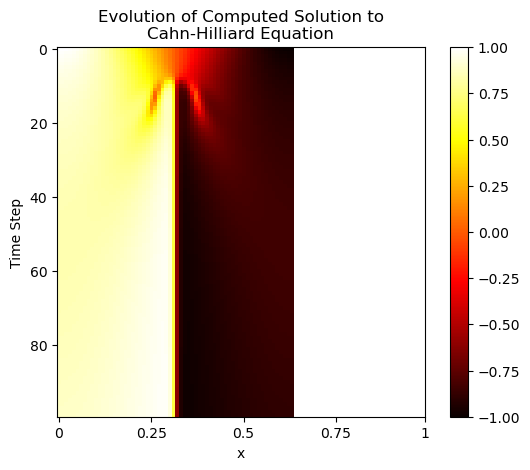

In [ ]:
plt.imshow(np.array(vals), cmap='hot', interpolation='nearest')
plt.xticks([0, 25, 50, 75, 99], [0, 0.25, 0.5, 0.75, 1])
plt.clim([-1, 1])
plt.colorbar()
plt.ylabel('Time Step')
plt.xlabel('x')
plt.title('Evolution of Computed Solution to\nCahn-Hilliard Equation')
plt.show()

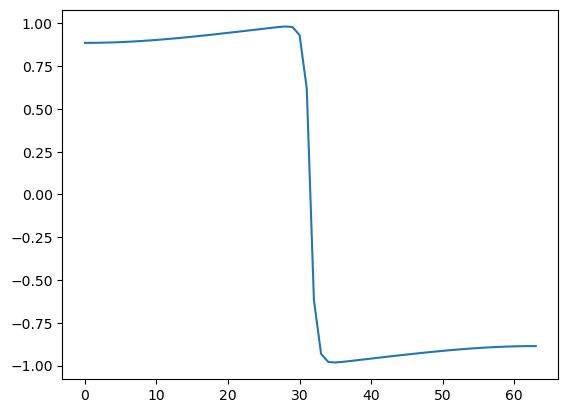

In [5]:
plt.plot(vals[-1])

In [11]:
print(vals[-1].sum() - vals[0].sum())

5.950795411990839e-14


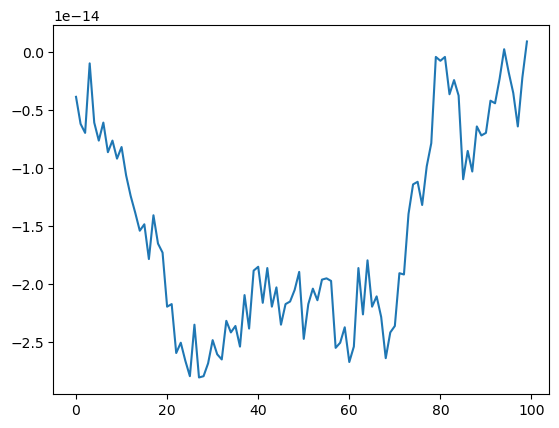

In [32]:
plt.plot([i.sum() for i in vals])

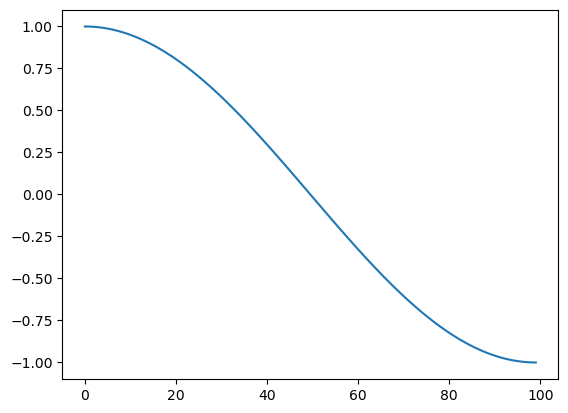

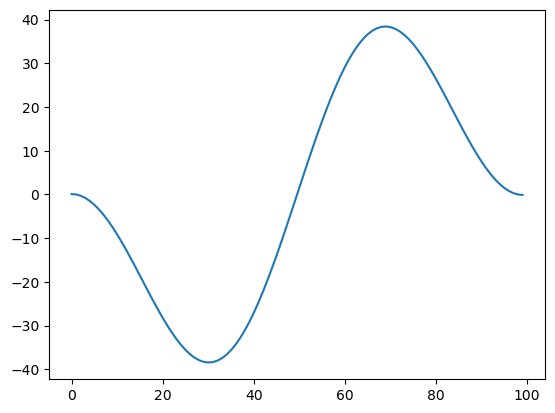

In [16]:
plt.plot(C0)
plt.show()
plt.plot(W0)